## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [5]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

!git clone https://github.com/willhk10-uva/A05-pca

with open('A05-pca/data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

fatal: destination path 'A05-pca' already exists and is not an empty directory.


Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

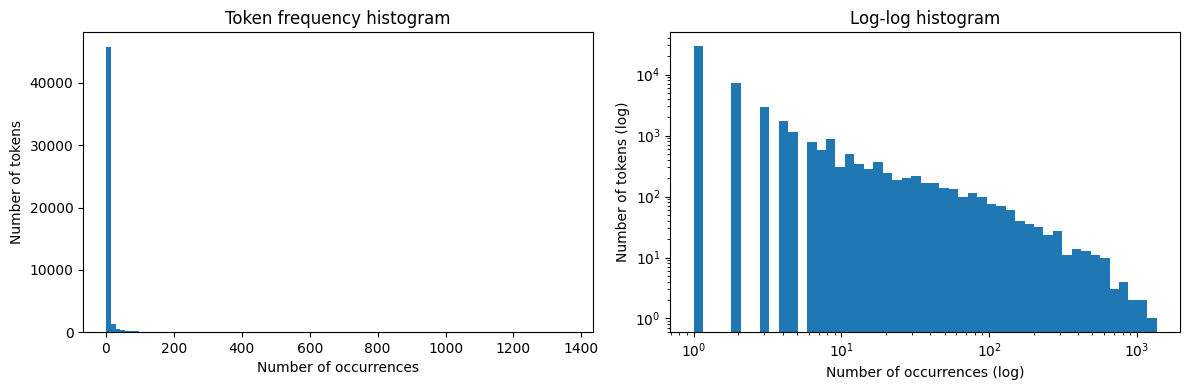

Distinct tokens: 48691
Tokens appearing only once: 29404
Top 10: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


In [6]:
counts = np.array(list(token_count.values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram of how often tokens occur
axes[0].hist(counts, bins=100)
axes[0].set_xlabel('Number of occurrences')
axes[0].set_ylabel('Number of tokens')
axes[0].set_title('Token frequency histogram')

# Same data on log scales so the shape is visible
axes[1].hist(counts, bins=np.logspace(0, np.log10(counts.max()), 50))
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Number of occurrences (log)')
axes[1].set_ylabel('Number of tokens (log)')
axes[1].set_title('Log-log histogram')

plt.tight_layout()
plt.show()

print(f"Distinct tokens: {len(counts)}")
print(f"Tokens appearing only once: {(counts == 1).sum()}")
print("Top 10:", token_freq[:10])

# The distribution of token counts is extremely right-skewed. In the linear
# histogram, almost all ~47,000 distinct tokens fall in the first bin (fewer than ~14 occurrences),
#with a long, nearly invisible tail out to ~1,400. The log-log plot shows the shape more clearly: about 30,000 tokens appear
# only once, the number of tokens drops steadily as frequency increases, and
# only a handful of tokens appear 1,000+ times. The roughly straight line on
# log-log axes suggests a power law (Zipf's law): a few very common tokens
# account for a large share of all occurrences, while most tokens are rare.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load data
df = pd.read_parquet('A05-pca/data/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop(columns='Email Type')

# 1. 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=125
)

# 2. Linear regression
reg = LinearRegression().fit(X_train, y_train)

print(f"Train R2: {reg.score(X_train, y_train):.4f}")
print(f"Test R2:  {reg.score(X_test, y_test):.4f}")

# 3. Largest coefficients in absolute value
coefs = pd.DataFrame({
    'token': X.columns,
    'coef': reg.coef_,
})
coefs['abs_coef'] = coefs['coef'].abs()
top = coefs.sort_values('abs_coef', ascending=False)
print(top.head(20))

Train R2: 0.7660
Test R2:  0.6702
                  token      coef  abs_coef
1504  background-image: -1.201203  1.201203
740           localized  0.815112  0.815112
906               aging  0.735023  0.735023
2362            thermal  0.590412  0.590412
1406         helvetica,  0.587472  0.587472
835        intervention -0.580474  0.580474
1302           erectile  0.575784  0.575784
1511            burning -0.569225  0.569225
1839              form.  0.560255  0.560255
2559            april's -0.525984  0.525984
818                cnet -0.495563  0.495563
2532             xanaax  0.490234  0.490234
2657              zdnet -0.487835  0.487835
1256             arial, -0.483577  0.483577
2365                rcs  0.464646  0.464646
2566         transcript  0.463811  0.463811
2229           quality,  0.451875  0.451875
1670               sais  0.441776  0.441776
2077         girlfriend  0.410499  0.410499
2701             ï¿½ï¿½  0.408999  0.408999


**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]